In [1]:
import glob
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.util as cutil
from scipy import stats

import numpy as np
time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    return ds_djf

def load_data(path):
    ens = []
    ds = []
    for p in glob.glob(path):
        ens.append(p.split('/')[-1].split('_')[4])
        ds.append(xr.open_dataset(p))
    data = xr.concat(ds, dim='ens')
    data['ens'] = ens

    return data


In [2]:
enso_nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv')
enso_nao_flags = enso_nao_flags.set_index(['model', 'realization'])
enso_nao_flags_new = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_change.csv')
enso_nao_flags_new = enso_nao_flags_new.set_index(['model', 'realization'])

In [3]:
path = "/sto4/data/Intermediate/VolMIP/pinatubo-full/"
path_piControl = "/sto4/data/Intermediate/VolMIP/piControl/"
models = ['CanESM5', 'GISS-E2-1-G','MPI-ESM1-2-LR', 'MIROC-ES2L'] # , 'UKESM1-0-LL']
colors = ['darkmagenta', 'darkorange', 'royalblue', 'limegreen'] # , 'deepskyblue']
plotdir = '/home/kperny/VolMIP_stratosphere/plots/surface_warming/'
precentage = 0.75

/tmp/ipykernel_2769392/2786450711.py:4: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
/tmp/ipykernel_2769392/2786450711.py:4: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
/tmp/ipykernel_2769392/3886317160.py:22: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.dateti

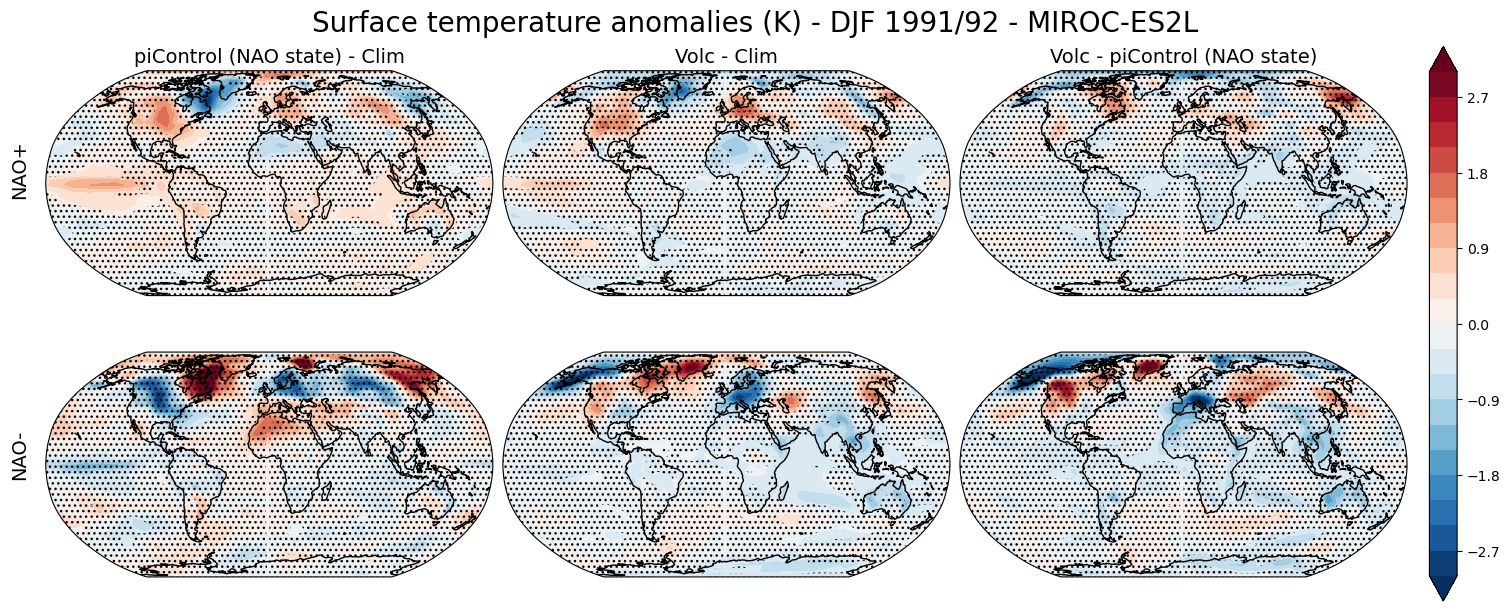

In [101]:
for model in models:
    clim = xr.open_dataset(glob.glob(path_piControl + model + '/tas_clim-djf_' + model + '*.nc')[0]).squeeze()

    picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
    picontrol['time'] = pd.date_range(str(picontrol.time[0].values).split('-')[0], str(int(str(picontrol.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')
    picontrolp = picontrol.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag==1).dropna().loc[model]['year'].values, method='nearest').squeeze()
    picontroln = picontrol.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag==-1).dropna().loc[model]['year'].values, method='nearest').squeeze()

    volc = load_data(path + model + '/tas_Amon_*fixed_dates.nc').squeeze()
    volcp = volc.sel(ens=enso_nao_flags_new.where((enso_nao_flags_new.experiment=='volc') & (enso_nao_flags_new.nao_flag==1)).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()
    volcn = volc.sel(ens=enso_nao_flags_new.where((enso_nao_flags_new.experiment=='volc') & (enso_nao_flags_new.nao_flag==-1)).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()

    plt.close()
    fig, axs = plt.subplots(2,3, figsize=(15,6), subplot_kw={'projection': ccrs.Robinson()}, layout='constrained')
    levels = np.linspace(-3,3,21)
    
    # PiControl (NAO+) - Clim
    cdata, clon, clat = cutil.add_cyclic((picontrolp.tas.mean('time') - clim.tas), picontrolp.lon, picontrolp.lat)
    c = axs[0,0].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signp = np.array(stats.ttest_ind(picontrolp.tas.values, picontrol.tas.values, axis=0, equal_var=False))[1,...]
    signp = np.nan_to_num(signp, nan=0.99)
    axs[0,0].contourf(picontrolp.lon, picontrolp.lat, signp,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['...',None], alpha=0.01,
                      transform=ccrs.PlateCarree())
    
    # PiControl (NAO-) - Clim
    cdata, clon, clat = cutil.add_cyclic((picontroln.tas.mean('time') - picontrolp.mean('time').tas), picontroln.lon, picontroln.lat)
    axs[1,0].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signn = np.array(stats.ttest_ind(picontroln.tas.values, picontrol.tas.values, axis=0, equal_var=False))[1,...]
    signn = np.nan_to_num(signn, nan=0.99)
    axs[1,0].contourf(picontroln.lon, picontroln.lat, signn,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['...',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    # VOLC (NAO+) - Clim
    cdata, clon, clat = cutil.add_cyclic((volcp.tas.mean('ens') - clim.tas), volcp.lon, volcp.lat)
    axs[0,1].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
    
    signp = np.array(stats.ttest_ind(volcp.tas.values, picontrol.tas.values, axis=0, equal_var=False))[1,...]
    signp = np.nan_to_num(signp, nan=0.99)
    axs[0,1].contourf(volcp.lon, volcp.lat, signp,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['...',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    # VOLC (NAO-) - Clim
    cdata, clon, clat = cutil.add_cyclic((volcn.tas.mean('ens') - clim.tas), volcn.lon, volcn.lat)
    axs[1,1].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
    
    signn = np.array(stats.ttest_ind(volcn.tas.values, picontrol.tas.values, axis=0, equal_var=False))[1,...]
    signn = np.nan_to_num(signn, nan=0.99)
    axs[1,1].contourf(volcn.lon, volcn.lat, signn,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['...',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    # VOLC (NAO+) - PiControl (NAO+)
    cdata, clon, clat = cutil.add_cyclic((volcp.tas.mean('ens') - picontrolp.mean('time').tas), volcp.lon, volcp.lat)
    axs[0,2].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signp = np.array(stats.ttest_ind(volcp.tas.values, picontrolp.tas.values, axis=0, equal_var=False))[1,...]
    signp = np.nan_to_num(signp, nan=0.99)
    axs[0,2].contourf(volcp.lon, volcp.lat, signp,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['...',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    # VOLC (NAO-) - PiControl (NAO-)
    cdata, clon, clat = cutil.add_cyclic((volcn.tas.mean('ens') - picontroln.mean('time').tas), volcn.lon, volcn.lat)
    axs[1,2].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signn = np.array(stats.ttest_ind(volcn.tas.values, picontroln.tas.values, axis=0, equal_var=False))[1,...]
    signn = np.nan_to_num(signn, nan=0.99)
    axs[1,2].contourf(volcn.lon, volcn.lat, signn,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['...',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    for ax in axs.flatten():
        ax.coastlines()
        
    axs[0,0].set_title('piControl (NAO state) - Clim', fontsize=14)
    axs[0,1].set_title('Volc - Clim', fontsize=14)
    axs[0,2].set_title('Volc - piControl (NAO state)', fontsize=14)

    axs[0,0].text(-0.08, 0.45, 'NAO+', transform=axs[0,0].transAxes, rotation=90, fontsize=14)
    axs[1,0].text(-0.08, 0.45, 'NAO-', transform=axs[1,0].transAxes, rotation=90, fontsize=14)

    plt.colorbar(c, ax=axs[0:2,2])

    fig.suptitle('Surface temperature anomalies (K) - DJF 1991/92 - ' + model, fontsize=20)
    plt.savefig(plotdir + 'all_' + model + '.png', dpi=200)

/tmp/ipykernel_2769392/2976841320.py:4: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
/tmp/ipykernel_2769392/2976841320.py:4: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
/tmp/ipykernel_2769392/3886317160.py:22: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.dateti

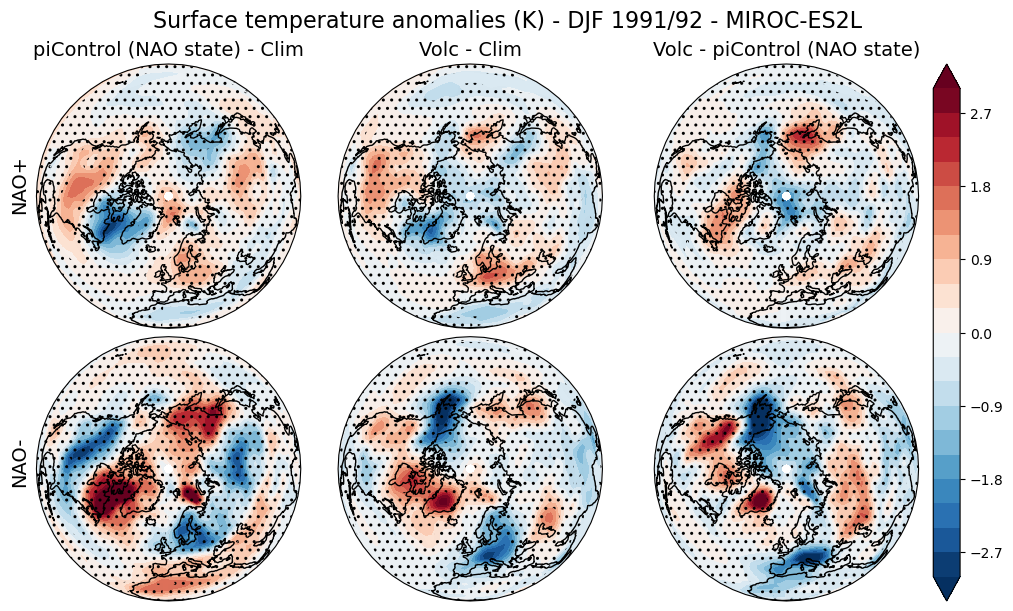

In [102]:
for model in models:
    clim = xr.open_dataset(glob.glob(path_piControl + model + '/tas_clim-djf_' + model + '*.nc')[0]).squeeze()

    picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
    picontrol['time'] = pd.date_range(str(picontrol.time[0].values).split('-')[0], str(int(str(picontrol.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')
    picontrolp = picontrol.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag==1).dropna().loc[model]['year'].values, method='nearest').squeeze()
    picontroln = picontrol.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag==-1).dropna().loc[model]['year'].values, method='nearest').squeeze()

    volc = load_data(path + model + '/tas_Amon_*fixed_dates.nc').squeeze()
    volcp = volc.sel(ens=enso_nao_flags_new.where((enso_nao_flags_new.experiment=='volc') & (enso_nao_flags_new.nao_flag==1)).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()
    volcn = volc.sel(ens=enso_nao_flags_new.where((enso_nao_flags_new.experiment=='volc') & (enso_nao_flags_new.nao_flag==-1)).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()

    plt.close()
    fig, axs = plt.subplots(2,3, figsize=(10,6), subplot_kw={'projection': ccrs.Orthographic(central_latitude=90)}, layout='constrained')
    levels = np.linspace(-3,3,21)

    # PiControl (NAO+) - Clim
    cdata, clon, clat = cutil.add_cyclic((picontrolp.tas.mean('time') - clim.tas), picontrolp.lon, picontrolp.lat)
    c = axs[0,0].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signp = np.array(stats.ttest_ind(picontrolp.tas.values, picontrol.tas.values, axis=0, equal_var=False))[1,...]
    signp = np.nan_to_num(signp, nan=0.99)
    axs[0,0].contourf(picontrolp.lon, picontrolp.lat, signp,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())
    
    # PiControl (NAO-) - Clim
    cdata, clon, clat = cutil.add_cyclic((picontroln.tas.mean('time') - picontrolp.mean('time').tas), picontroln.lon, picontroln.lat)
    axs[1,0].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signn = np.array(stats.ttest_ind(picontroln.tas.values, picontrol.tas.values, axis=0, equal_var=False))[1,...]
    signn = np.nan_to_num(signn, nan=0.99)
    axs[1,0].contourf(picontroln.lon, picontroln.lat, signn,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    # VOLC (NAO+) - Clim
    cdata, clon, clat = cutil.add_cyclic((volcp.tas.mean('ens') - clim.tas), volcp.lon, volcp.lat)
    axs[0,1].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
    
    signp = np.array(stats.ttest_ind(volcp.tas.values, picontrol.tas.values, axis=0, equal_var=False))[1,...]
    signp = np.nan_to_num(signp, nan=0.99)
    axs[0,1].contourf(volcp.lon, volcp.lat, signp,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    # VOLC (NAO-) - Clim
    cdata, clon, clat = cutil.add_cyclic((volcn.tas.mean('ens') - clim.tas), volcn.lon, volcn.lat)
    axs[1,1].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
    
    signn = np.array(stats.ttest_ind(volcn.tas.values, picontrol.tas.values, axis=0, equal_var=False))[1,...]
    signn = np.nan_to_num(signn, nan=0.99)
    axs[1,1].contourf(volcn.lon, volcn.lat, signn,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    # VOLC (NAO+) - PiControl (NAO+)
    cdata, clon, clat = cutil.add_cyclic((volcp.tas.mean('ens') - picontrolp.mean('time').tas), volcp.lon, volcp.lat)
    axs[0,2].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signp = np.array(stats.ttest_ind(volcp.tas.values, picontrolp.tas.values, axis=0, equal_var=False))[1,...]
    signp = np.nan_to_num(signp, nan=0.99)
    axs[0,2].contourf(volcp.lon, volcp.lat, signp,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    # VOLC (NAO-) - PiControl (NAO-)
    cdata, clon, clat = cutil.add_cyclic((volcn.tas.mean('ens') - picontroln.mean('time').tas), volcn.lon, volcn.lat)
    axs[1,2].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signn = np.array(stats.ttest_ind(volcn.tas.values, picontroln.tas.values, axis=0, equal_var=False))[1,...]
    signn = np.nan_to_num(signn, nan=0.99)
    axs[1,2].contourf(volcn.lon, volcn.lat, signn,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    for ax in axs.flatten():
        ax.coastlines()

    axs[0,0].set_title('piControl (NAO state) - Clim', fontsize=14)
    axs[0,1].set_title('Volc - Clim', fontsize=14)
    axs[0,2].set_title('Volc - piControl (NAO state)', fontsize=14)

    axs[0,0].text(-0.1, 0.45, 'NAO+', transform=axs[0,0].transAxes, rotation=90, fontsize=14)
    axs[1,0].text(-0.1, 0.45, 'NAO-', transform=axs[1,0].transAxes, rotation=90, fontsize=14)
    
    plt.colorbar(c, ax=axs[0:2,2])

    fig.suptitle('Surface temperature anomalies (K) - DJF 1991/92 - ' + model, fontsize=16)
    plt.savefig(plotdir + 'polar_' + model + '.png', dpi=200)

/tmp/ipykernel_996027/2838408407.py:8: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
/tmp/ipykernel_996027/2838408407.py:8: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
/tmp/ipykernel_996027/3886317160.py:22: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime 

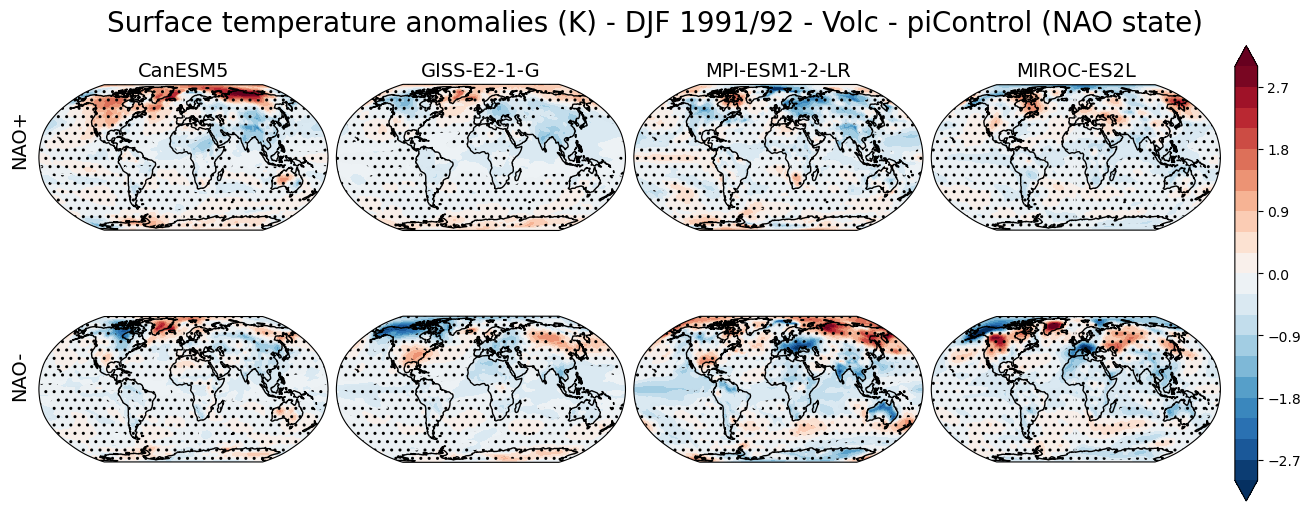

In [8]:
# all models but only volc - picontrol (NAO+ / NAO-)
fig, axs = plt.subplots(2,4, figsize=(13,5), subplot_kw={'projection': ccrs.Robinson()}, layout='constrained')
levels = np.linspace(-3,3,21)

for i, model in enumerate(models):
    clim = xr.open_dataset(glob.glob(path_piControl + model + '/tas_clim-djf_' + model + '*.nc')[0]).squeeze()

    picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
    picontrol['time'] = pd.date_range(str(picontrol.time[0].values).split('-')[0], str(int(str(picontrol.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')
    picontrolp = picontrol.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag==1).dropna().loc[model]['year'].values, method='nearest').squeeze()
    picontroln = picontrol.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag==-1).dropna().loc[model]['year'].values, method='nearest').squeeze()

    volc = load_data(path + model + '/tas_Amon_*fixed_dates.nc').squeeze()
    volcp = volc.sel(ens=enso_nao_flags_new.where((enso_nao_flags_new.experiment=='volc') & (enso_nao_flags_new.nao_flag==1)).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()
    volcn = volc.sel(ens=enso_nao_flags_new.where((enso_nao_flags_new.experiment=='volc') & (enso_nao_flags_new.nao_flag==-1)).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()

    
    # VOLC (NAO+) - PiControl (NAO+)
    cdata, clon, clat = cutil.add_cyclic((volcp.tas.mean('ens') - picontrolp.mean('time').tas), volcp.lon, volcp.lat)
    c = axs[0,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signp = np.array(stats.ttest_ind(volcp.tas.values, picontrolp.tas.values, axis=0, equal_var=False))[1,...]
    signp = np.nan_to_num(signp, nan=0.99)
    axs[0,i].contourf(volcp.lon, volcp.lat, signp,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    # VOLC (NAO-) - PiControl (NAO-)
    cdata, clon, clat = cutil.add_cyclic((volcn.tas.mean('ens') - picontroln.mean('time').tas), volcn.lon, volcn.lat)
    axs[1,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signn = np.array(stats.ttest_ind(volcn.tas.values, picontroln.tas.values, axis=0, equal_var=False))[1,...]
    signn = np.nan_to_num(signn, nan=0.99)
    axs[1,i].contourf(volcn.lon, volcn.lat, signn,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())
    
    axs[0,i].set_title(model, fontsize=14)

for ax in axs.flatten():
    ax.coastlines()

axs[0,0].text(-0.1, 0.45, 'NAO+', transform=axs[0,0].transAxes, rotation=90, fontsize=14)
axs[1,0].text(-0.1, 0.45, 'NAO-', transform=axs[1,0].transAxes, rotation=90, fontsize=14)
plt.colorbar(c, ax=axs[0:2,3])
plt.suptitle('Surface temperature anomalies (K) - DJF 1991/92 - Volc - piControl (NAO state)', fontsize=20)
plt.savefig(plotdir + 'all_models_volc-picontrol.png', dpi=200)

/tmp/ipykernel_996027/1567882683.py:8: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
/tmp/ipykernel_996027/1567882683.py:8: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
/tmp/ipykernel_996027/3886317160.py:22: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime 

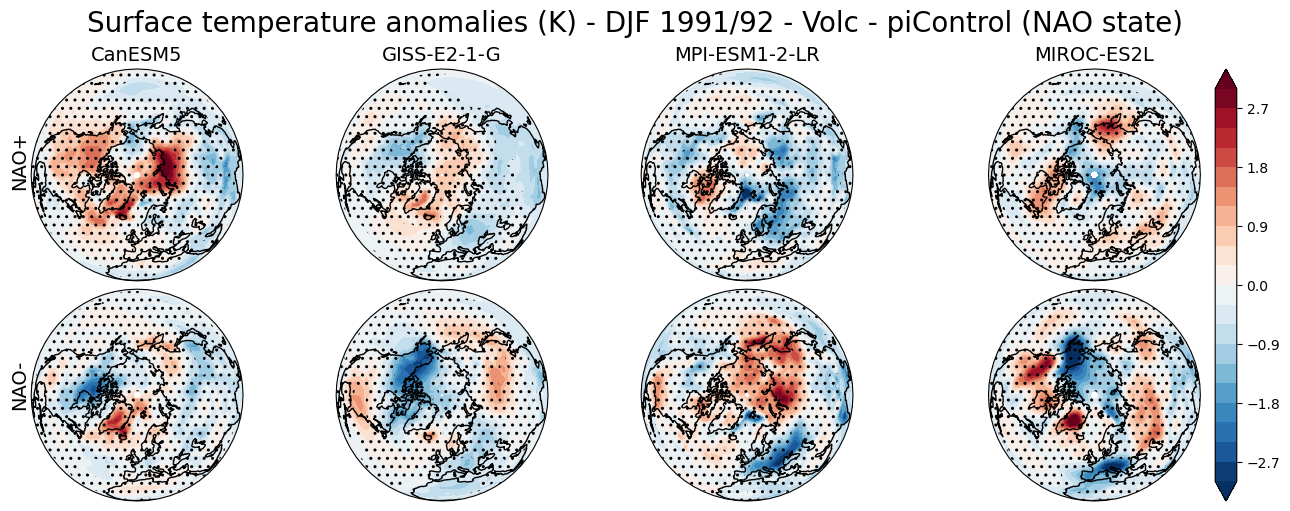

In [9]:
# all models but only volc - picontrol (NAO+ / NAO-)
fig, axs = plt.subplots(2,4, figsize=(13,5), subplot_kw={'projection': ccrs.Orthographic(central_latitude=90)}, layout='constrained')
levels = np.linspace(-3,3,21)

for i, model in enumerate(models):
    clim = xr.open_dataset(glob.glob(path_piControl + model + '/tas_clim-djf_' + model + '*.nc')[0]).squeeze()

    picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
    picontrol['time'] = pd.date_range(str(picontrol.time[0].values).split('-')[0], str(int(str(picontrol.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')
    picontrolp = picontrol.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag==1).dropna().loc[model]['year'].values, method='nearest').squeeze()
    picontroln = picontrol.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag==-1).dropna().loc[model]['year'].values, method='nearest').squeeze()

    volc = load_data(path + model + '/tas_Amon_*fixed_dates.nc').squeeze()
    volcp = volc.sel(ens=enso_nao_flags_new.where((enso_nao_flags_new.experiment=='volc') & (enso_nao_flags_new.nao_flag==1)).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()
    volcn = volc.sel(ens=enso_nao_flags_new.where((enso_nao_flags_new.experiment=='volc') & (enso_nao_flags_new.nao_flag==-1)).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()
    
    # VOLC (NAO+) - PiControl (NAO+)
    cdata, clon, clat = cutil.add_cyclic((volcp.tas.mean('ens') - picontrolp.mean('time').tas), volcp.lon, volcp.lat)
    c = axs[0,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signp = np.array(stats.ttest_ind(volcp.tas.values, picontrolp.tas.values, axis=0, equal_var=False))[1,...]
    signp = np.nan_to_num(signp, nan=0.99)
    axs[0,i].contourf(volcp.lon, volcp.lat, signp,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    # VOLC (NAO-) - PiControl (NAO-)
    cdata, clon, clat = cutil.add_cyclic((volcn.tas.mean('ens') - picontroln.mean('time').tas), volcn.lon, volcn.lat)
    axs[1,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signn = np.array(stats.ttest_ind(volcn.tas.values, picontroln.tas.values, axis=0, equal_var=False))[1,...]
    signn = np.nan_to_num(signn, nan=0.99)
    axs[1,i].contourf(volcn.lon, volcn.lat, signn,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())
    
    axs[0,i].set_title(model, fontsize=14)

for ax in axs.flatten():
    ax.coastlines()

axs[0,0].text(-0.1, 0.45, 'NAO+', transform=axs[0,0].transAxes, rotation=90, fontsize=14)
axs[1,0].text(-0.1, 0.45, 'NAO-', transform=axs[1,0].transAxes, rotation=90, fontsize=14)
plt.colorbar(c, ax=axs[0:2,3])
plt.suptitle('Surface temperature anomalies (K) - DJF 1991/92 - Volc - piControl (NAO state)', fontsize=20)
plt.savefig(plotdir + 'all_models_polar_volc-picontrol.png', dpi=200)